In [1]:
import numpy as np
import matplotlib.pyplot as plt

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

In [2]:
for p in [0.6, 0.9, 0.99, 0.99999]:
    squared = (p - 0) ** 2
    log_loss = -np.log(1 - p)
    print(f"predicted {p:<8} squared error = {squared:.5f}   log-loss = {log_loss:.2f}")

predicted 0.6      squared error = 0.36000   log-loss = 0.92
predicted 0.9      squared error = 0.81000   log-loss = 2.30
predicted 0.99     squared error = 0.98010   log-loss = 4.61
predicted 0.99999  squared error = 0.99998   log-loss = 11.51


## Log-loss, for one example and for a whole dataset

In [3]:
def log_loss_one(prediction, actual):
    if actual == 1:
        return -np.log(prediction)
    return -np.log(1 - prediction)

def log_loss(predictions, actual):
    m = len(actual)
    total = 0
    for i in range(m):
        total += log_loss_one(predictions[i], actual[i])
    return total / m

def log_loss_vectorized(predictions, actual):
    return -np.mean(actual * np.log(predictions) + (1 - actual) * np.log(1 - predictions))

two_day_predictions = np.array([0.9, 0.2])
two_day_actual = np.array([1, 0])

print("Loop version:      ", round(log_loss(two_day_predictions, two_day_actual), 4))
print("Vectorized version:", round(log_loss_vectorized(two_day_predictions, two_day_actual), 4))

Loop version:       0.1643
Vectorized version: 0.1643


## The two loss curves for a single example

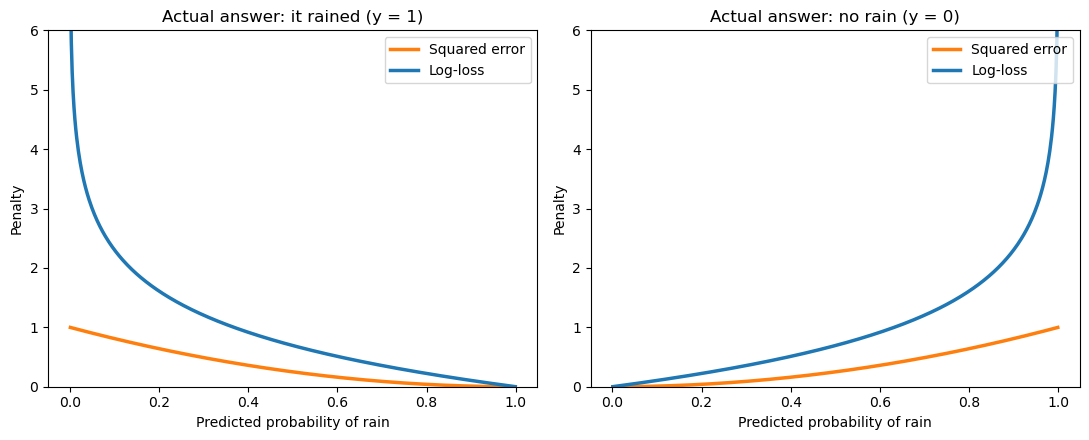

In [4]:
p = np.linspace(0.001, 0.999, 500)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, y_val in zip(axes, [1, 0]):
    squared = (p - y_val) ** 2
    ll = -np.log(p) if y_val == 1 else -np.log(1 - p)
    ax.plot(p, squared, color='tab:orange', lw=2.5, label='Squared error')
    ax.plot(p, ll, color='tab:blue', lw=2.5, label='Log-loss')
    ax.set_ylim(0, 6)
    ax.set_xlabel('Predicted probability of rain')
    ax.set_ylabel('Penalty')
    ax.set_title('Actual answer: it rained (y = 1)' if y_val == 1 else 'Actual answer: no rain (y = 0)')
    ax.legend(loc='upper right')
plt.tight_layout()
plt.savefig('loss_curves.png', dpi=150)
plt.show()

## Why gradients go quiet with squared error

In [5]:
z = -8
y = 1
p = sigmoid(z)

slope_squared = (p - y) * p * (1 - p)
slope_log_loss = p - y

print("Predicted chance of rain:", round(p, 5))
print("Squared error slope on z:", round(slope_squared, 5))
print("Log-loss slope on z:     ", round(slope_log_loss, 5))
print("Log-loss pushes about", round(slope_log_loss / slope_squared), "times harder")

Predicted chance of rain: 0.00034
Squared error slope on z: -0.00034
Log-loss slope on z:      -0.99966
Log-loss pushes about 2983 times harder


## The rain data

In [6]:
darkness = np.array([1, 2, 3, 4, 5, 6, 7, 8], dtype=float)
rained = np.array([0, 0, 0, 0, 1, 1, 1, 1], dtype=float)

def cost_squared_error(w, b):
    p = sigmoid(w * darkness + b)
    return np.mean((p - rained) ** 2) / 2

def cost_log_loss(w, b):
    p = np.clip(sigmoid(w * darkness + b), 1e-12, 1 - 1e-12)
    return -np.mean(rained * np.log(p) + (1 - rained) * np.log(1 - p))

def slopes_squared_error(w, b):
    p = sigmoid(w * darkness + b)
    d = (p - rained) * p * (1 - p)      # the tiny p(1-p) factor
    return np.mean(d * darkness), np.mean(d)

def slopes_log_loss(w, b):
    p = sigmoid(w * darkness + b)
    d = p - rained                      # just prediction minus actual
    return np.mean(d * darkness), np.mean(d)

def run(slopes, w, b, learning_rate, steps):
    for _ in range(steps):
        slope_w, slope_b = slopes(w, b)
        w = w - learning_rate * slope_w
        b = b - learning_rate * slope_b
    return w, b

## Same bad start, same learning rate, two cost functions

Start: w = -3, b = 10.

In [7]:
start_w, start_b = -3.0, 10.0

w_sq, b_sq = run(slopes_squared_error, start_w, start_b, 0.1, 10000)
w_ll, b_ll = run(slopes_log_loss, start_w, start_b, 0.1, 10000)

print(f"Squared error -> w = {w_sq:.2f}, b = {b_sq:.2f}, cost = {cost_squared_error(w_sq, b_sq):.4f}")
print(f"Log-loss      -> w = {w_ll:.2f}, b = {b_ll:.2f}, cost = {cost_log_loss(w_ll, b_ll):.4f}")

Squared error -> w = -8.53, b = 5.74, cost = 0.2502
Log-loss      -> w = 3.13, b = -13.96, cost = 0.0501


In [8]:
w_long, b_long = run(slopes_squared_error, start_w, start_b, 0.1, 200000)
print(f"Squared error after 200,000 steps -> w = {w_long:.2f}, b = {b_long:.2f}, cost = {cost_squared_error(w_long, b_long):.4f}")
print("Predictions:", np.round(sigmoid(w_long * darkness + b_long), 3))

Squared error after 200,000 steps -> w = -9.42, b = 4.85, cost = 0.2500
Predictions: [0.01 0.   0.   0.   0.   0.   0.   0.  ]


## But squared error does not always fail

In [9]:
w0, b0 = run(slopes_squared_error, 0.0, 0.0, 0.1, 3000)
print(f"Squared error from zero -> w = {w0:.2f}, b = {b0:.2f}, cost = {cost_squared_error(w0, b0):.4f}")

Squared error from zero -> w = 0.96, b = -4.12, cost = 0.0245


## The two cost surfaces, with the gradient descent paths

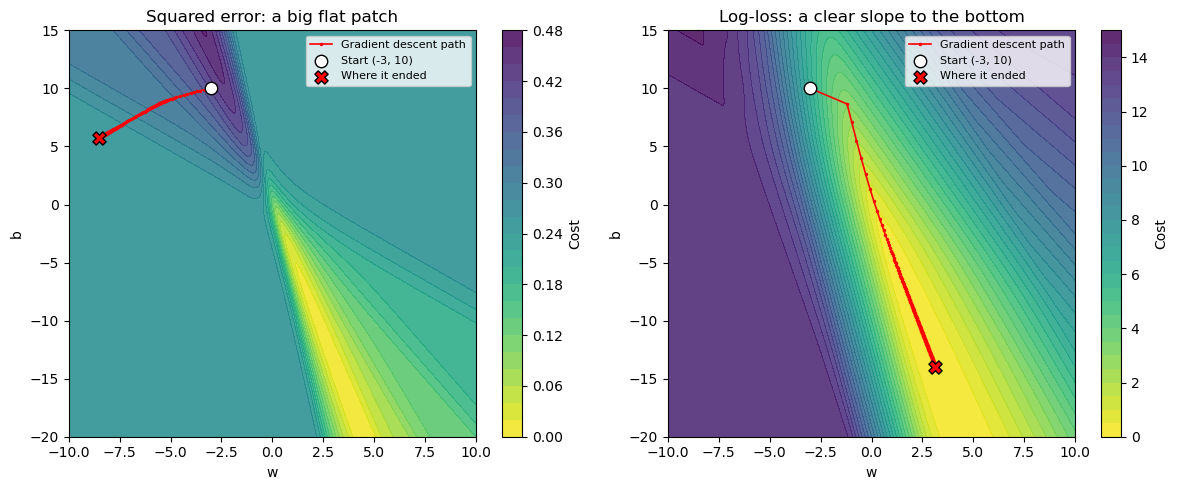

In [10]:
def path(slopes, w, b, learning_rate, steps, every):
    points = [(w, b)]
    for i in range(steps):
        slope_w, slope_b = slopes(w, b)
        w = w - learning_rate * slope_w
        b = b - learning_rate * slope_b
        if (i + 1) % every == 0:
            points.append((w, b))
    return np.array(points)

W, B = np.meshgrid(np.linspace(-10, 10, 200), np.linspace(-20, 15, 200))
C_sq = np.vectorize(cost_squared_error)(W, B)
C_ll = np.vectorize(cost_log_loss)(W, B)

path_sq = path(slopes_squared_error, start_w, start_b, 0.1, 10000, 50)
path_ll = path(slopes_log_loss, start_w, start_b, 0.1, 10000, 50)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
panels = [(axes[0], C_sq, path_sq, 'Squared error: a big flat patch', 25),
          (axes[1], C_ll, path_ll, 'Log-loss: a clear slope to the bottom', 30)]
for ax, C, pth, title, levels in panels:
    cs = ax.contourf(W, B, C, levels=levels, cmap='viridis_r', alpha=0.85)
    ax.plot(pth[:, 0], pth[:, 1], 'r.-', ms=3, lw=1.2, label='Gradient descent path')
    ax.scatter([start_w], [start_b], c='white', edgecolor='black', s=80, zorder=5, label='Start (-3, 10)')
    ax.scatter([pth[-1, 0]], [pth[-1, 1]], c='red', edgecolor='black', marker='X', s=90, zorder=5, label='Where it ended')
    ax.set_xlabel('w'); ax.set_ylabel('b'); ax.set_title(title)
    ax.legend(fontsize=8, loc='upper right')
    plt.colorbar(cs, ax=ax, label='Cost')
plt.tight_layout()
plt.savefig('cost_surfaces.png', dpi=150)
plt.show()